# Vision — Semi-supervised (sedikit gambar berlabel, banyak tanpa label)
**Kapan dipakai:** hanya sebagian kecil gambar train yang berlabel, sisanya label kosong.

**Langkah (self-training / pseudo-label):** latih di yang berlabel → tebak yang tanpa label →
tebakan yang sangat yakin (≥ `CONFIDENCE`) dijadikan label → latih ulang → ulangi beberapa
putaran. Putaran terbaik dipilih dengan validasi. Pembanding: `LabelSpreading` (label menyebar
ke tetangga terdekat di ruang embedding).

**Data demo:** CIFAR-10 kecil, hanya 5% label train yang dipakai.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import LabelSpreading
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "Z:/GEMASTIK-DATABASE/pretrained"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
LABELED_FRACTION = 0.05   # HANYA DEMO: bagian label yang dipakai
CONFIDENCE = 0.90         # pseudo-label hanya untuk tebakan dengan probabilitas >= ini
N_ROUNDS = 5
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = np.array([0.485, 0.456, 0.406])   # normalisasi warna ImageNet
STD = np.array([0.229, 0.224, 0.225])

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)

train: (4000, 2) | test: (1000, 2)


## Sembunyikan sebagian besar label (HANYA DEMO)
Saat lomba: hapus sel ini, ganti dengan `train["used_label"] = train[TARGET]`
(baris yang labelnya kosong otomatis jadi "tanpa label").

In [4]:
labeled_rows, _ = train_test_split(np.arange(len(train)), train_size=LABELED_FRACTION,
                                   random_state=SEED, stratify=train[TARGET])
used_labels = np.full(len(train), None, dtype=object)
used_labels[labeled_rows] = train[TARGET].to_numpy()[labeled_rows]
train["used_label"] = used_labels
print("berlabel:", train["used_label"].notna().sum(),
      "| tanpa label:", train["used_label"].isna().sum())

berlabel: 200 | tanpa label: 3800


## Embedding ResNet18 pretrained (beku)

In [5]:
backbone = models.resnet18(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE)
backbone.eval()


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        arrays = []
        for path in paths[start:start + BATCH_SIZE]:
            image = Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")
            image = image.resize((IMAGE_SIZE, IMAGE_SIZE))
            arrays.append((np.asarray(image) / 255 - MEAN) / STD)
        batch = torch.tensor(np.stack(arrays), dtype=torch.float32)
        batch = batch.permute(0, 3, 1, 2).to(DEVICE)
        with torch.no_grad():
            batches.append(backbone(batch).cpu().numpy())
    return np.concatenate(batches)


X_train = embed_images(list(train[PATH_COL]))
X_test = embed_images(list(test[PATH_COL]))
print("train:", X_train.shape, "| test:", X_test.shape)

train: (4000, 512) | test: (1000, 512)


## Validasi dari data berlabel
30% data berlabel disisihkan (tidak dilatih, tidak diberi pseudo-label) untuk memilih putaran.

In [6]:
labeled = np.where(train["used_label"].notna())[0]
val_rows, _ = train_test_split(labeled, train_size=0.3, random_state=SEED,
                               stratify=train["used_label"].iloc[labeled])
X_val = X_train[val_rows]
y_val = train["used_label"].iloc[val_rows].astype(str)
is_val = np.zeros(len(train), dtype=bool)
is_val[val_rows] = True
print("validasi:", len(val_rows))

validasi: 60


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai. Model harus punya `predict_proba`.

In [7]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
# model = KNeighborsClassifier(n_neighbors=10, metric="cosine")

## Self-training
Putaran 0 = hanya label asli (baseline). Tiap putaran menambah pseudo-label yang yakin.
`clone(model)` = salinan model yang belum dilatih. Validasi kecil membuat pilihan putaran
kasar; kalau validasi tidak naik, putaran 0 = pilihan aman.

In [8]:
working_labels = train["used_label"].to_numpy().copy()
working_labels[is_val] = None
round_models = []
val_scores = []
label_counts = []
for round_number in range(N_ROUNDS + 1):
    has_label = pd.notna(working_labels)
    round_model = clone(model)
    round_model.fit(X_train[has_label], working_labels[has_label].astype(str))
    round_models.append(round_model)
    val_scores.append(f1_score(y_val, round_model.predict(X_val), average="macro"))
    label_counts.append(has_label.sum())

    # pseudo-label: baris tanpa label (bukan validasi) yang tebakannya sangat yakin
    unlabeled_rows = np.where(~has_label & ~is_val)[0]
    proba = round_model.predict_proba(X_train[unlabeled_rows])
    confident = proba.max(axis=1) >= CONFIDENCE
    new_labels = round_model.classes_[proba[confident].argmax(axis=1)]
    working_labels[unlabeled_rows[confident]] = new_labels

history = pd.DataFrame()
history["round"] = range(N_ROUNDS + 1)
history["n_labels"] = label_counts
history["f1_val"] = val_scores
best_round = int(np.argmax(val_scores))
print("putaran terbaik menurut validasi:", best_round)
history.round(4)

putaran terbaik menurut validasi: 3


,round,n_labels,f1_val
0,0,140,0.7771
1,1,1464,0.7292
2,2,2492,0.7608
3,3,2907,0.7780
4,4,3067,0.7630
5,5,3143,0.7442


## Kurva skor validasi vs putaran

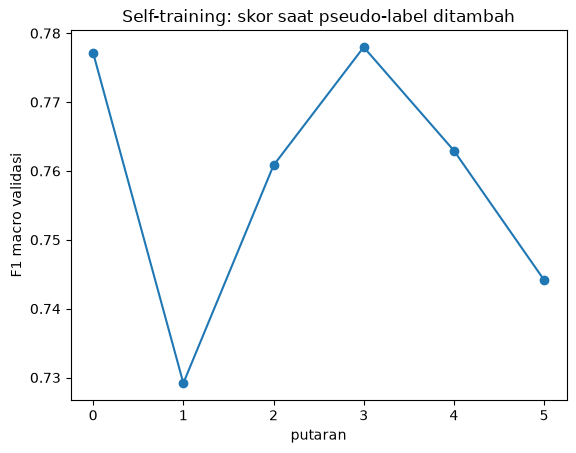

In [9]:
plt.plot(history["round"], history["f1_val"], marker="o")
plt.xlabel("putaran")
plt.ylabel("F1 macro validasi")
plt.title("Self-training: skor saat pseudo-label ditambah")
plt.savefig("kurva.png", dpi=150, bbox_inches="tight")
plt.show()

## Pembanding: LabelSpreading
Label kosong (dan validasi) diberi -1. Label menyebar ke 10 tetangga terdekat.

In [10]:
class_names = sorted(train["used_label"].dropna().unique())
spread_labels = np.full(len(train), -1)
for number, name in enumerate(class_names):
    spread_labels[train["used_label"].to_numpy() == name] = number
spread_labels[is_val] = -1

scaler = StandardScaler().fit(X_train)
spread = LabelSpreading(kernel="knn", n_neighbors=10, max_iter=100)
spread.fit(scaler.transform(X_train), spread_labels)
spread_val = np.array(class_names)[spread.predict(scaler.transform(X_val))]
spread_test = np.array(class_names)[spread.predict(scaler.transform(X_test))]
print("F1 validasi LabelSpreading:", round(f1_score(y_val, spread_val, average="macro"), 4))
print("F1 validasi self-training :", round(val_scores[best_round], 4))

F1 validasi LabelSpreading: 0.5498
F1 validasi self-training : 0.778


## Submission (model dari putaran terbaik menurut validasi)

In [11]:
model = round_models[best_round]
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,airplane
1,2,airplane
2,3,airplane
3,4,airplane
4,5,airplane


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Skor test tiap putaran: apakah putaran pilihan validasi memang bagus?

In [12]:
test_key = pd.read_csv(TEST_KEY_CSV)[TARGET]
test_scores = []
for round_model in round_models:
    test_scores.append(f1_score(test_key, round_model.predict(X_test), average="macro"))
history["f1_test"] = test_scores
print(history.round(4))
print("F1 test LabelSpreading:", round(f1_score(test_key, spread_test, average="macro"), 4))

   round  n_labels  f1_val  f1_test
0      0       140  0.7771   0.7588
1      1      1464  0.7292   0.7928
2      2      2492  0.7608   0.8099
3      3      2907  0.7780   0.8048
4      4      3067  0.7630   0.8080
5      5      3143  0.7442   0.8126
F1 test LabelSpreading: 0.5786
